# Tail experiments: an FWM tail trained with every error channel on

**Question (user, 2026-11-11).** Take the best FWM tail of `FWM_tails.ipynb` (the 0.8 μs tail after the EsT X gate,
trained with the decay set only). Retrain it with **all of Shirol's error channels** on. Then score gate + tail against the
gate alone, also with all channels on. Does the tail beat the gate alone (break even)?

## Setup

**The code.** Shirol's odd kitten code: $|0_L\rangle = (|1\rangle + |5\rangle)/\sqrt2$, $|1_L\rangle = |3\rangle$. One photon
loss turns the code words into *error words* with an even photon number, which the tail can repair.

**The chip.** Shirol et al., PRX 16, 021042, Table I (`AQEC/device.py`). States $|n, j, m\rangle$ = storage photons ×
transmon (g, e, f) × readout photons. The higher-order terms (storage Kerr, $\chi'$) are on everywhere.

**The gate.** The EsT X gate of `FWM_tails.ipynb` (seed 24 of the $C_{\rm err}$ cost, `u_X_est_err_closed_s24.npy`), 1.1 μs
on a 2 ns grid. It is not retrained here. It runs at storage truncation $n_c = 24$, and its output is cut to $n_c = 16$
for the tail, as in all earlier tail training.

**The tail.** 0.8 μs in which only the two FWM combs act (linear drives off). Each comb is one complex waveform
$\eta_c(t)$, capped at $|\eta_c| \le 0.1$. Method, frame and cost are those of `FWM_tails.ipynb` §4, unchanged. The only
new thing is the list of jump operators.

**Words and symbols.**

| term | meaning |
|---|---|
| tail | the time after the gate in which only the two FWM combs act |
| comb 1, comb 2 | comb 1 puts a lost photon back and lifts the transmon $g \to f$; comb 2 moves that excitation into the readout, which leaks it away |
| $\eta_c(t)$ | the control: one complex waveform per comb $c$, capped at $\lvert\eta_c\rvert \le 0.1$ |
| $F_{\rm pro}$ | process fidelity on the code against the ideal X gate, readout traced out. Gains in % are percentage points of $F_{\rm pro}$ |
| gain | $F_{\rm pro}$(gate + tail) − $F_{\rm pro}$(gate alone), both scored with the same noise |
| decay set | photon loss $\kappa_a$, readout decay $\kappa_r$, transmon decay $T_1$ ($e\to g$, $f \to e$): what every earlier tail was trained with |
| Shirol full set | the decay set plus transmon heating ($g\to e$, $e \to f$, with the pumps' extra heating), storage heating, and pure dephasing of transmon and storage. `AQEC/master_equation.collapse_operators` default; `noise="shirol"` in `DGRAPE` |
| DGRAPE all_ch | the older "all channels" set of `FWM_tails.ipynb` §6.5: dephasing + heating, but no $e\to f$ heating, no pump heating and the full storage dephasing |
| QEC teeth | Shirol's Table II comb strengths held constant: a fixed reference tail and one of the two training starts (tag `t2`) |
| idle | the gate followed by 0.8 μs of nothing: what waiting costs |
| $n_c$ | number of storage Fock levels kept in the simulation |

In [1]:
import json
import os
import sys

if os.path.basename(os.path.abspath(".")) == "notebooks":   # the notebook lives in notebooks/; data paths are relative to the repo root
    os.chdir("..")
REPO_ROOT = os.path.abspath(".")
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from joblib import Parallel, delayed

from AQEC import device as dev
from AQEC import master_equation as me
from DGRAPE import fwm
from DGRAPE import fwm_tail as ft
from DGRAPE.model import rates as dgrape_rates, shirol_collapse_ops

np.seterr(divide="ignore", over="ignore", invalid="ignore")

DT = ft.DT
TAIL_US = 0.8
GATE = "pulses/dgrape/u_X_est_err_closed_s24.npy"       # the EsT X gate ("EsT-good", seed 24), 1.1 us
TAGS = {"decay, QEC-teeth start": "X_tail_estg_T08_t2", "decay, zero start": "X_tail_estg_T08_z",
        "all channels, from t2": "X_tail_estg_T08_shirol_t2", "all channels, from z": "X_tail_estg_T08_shirol_z"}
OKABE = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#D55E00", "#56B4E9"]
os.makedirs("figures", exist_ok=True)


def tidy(ax, grid=True):
    if grid:
        ax.grid(color="0.9", lw=0.6)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)


def load_run(tag):
    with open(f"pulses/dgrape/{tag}.json") as f:
        return json.load(f), np.load(f"pulses/dgrape/eta_{tag}.npy")


RUNS = {label: load_run(tag) for label, tag in TAGS.items()}
print({label: f"{info['F_pro']:.6f} ({info.get('channels', 'decay')})" for label, (info, _) in RUNS.items()})

{'decay, QEC-teeth start': '0.970272 (decay)', 'decay, zero start': '0.970242 (decay)', 'all channels, from t2': '0.960364 (shirol)', 'all channels, from z': '0.960326 (shirol)'}


## 1. The question and the break-even rule

The earlier tails were trained with the decay set. Under it the best one (0.8 μs, QEC-teeth start) gains **+0.32 %** over
the gate alone (`FWM_tails.ipynb` §6). Scored with DGRAPE's older all-channel set it gains only **+0.03 %**
(`FWM_tails.ipynb` §6.5). So the extra noise eats almost all of the gain. Two things could be true:

1. the tail is right, and the extra noise simply costs more during its 0.8 μs, or
2. a tail trained *knowing* about the extra noise would do better.

Here we test (2). We warm-start from the two decay-trained 0.8 μs tails (the QEC-teeth start `t2` and the zero start
`z`), switch every Shirol channel on, and train 600 more iterations.

**Break-even rule (fixed before training).** The tail breaks even if

$$\text{gain} = F_{\rm pro}(\text{gate + tail}) - F_{\rm pro}(\text{gate alone}) > 0$$

with the Shirol full set on in both, **both** at the training truncation ($n_c = 16$, gate output cut from 24) **and**
held out at $n_c = 28$ (gate and tail both run there, no cut), for the better of the two starts. The spread between the two
starts is reported next to it.

## 2. The noise model

Table 1 lists every jump operator. "Shirol full set" is what we train and score with. It differs from DGRAPE's older
`all_ch` set in three ways:

- **Heating on $e \to f$** as well as $g \to e$, at the same up/down ratio.
- **Pump-driven heating.** Shirol's App. D measures an extra $\Delta\gamma_\uparrow = 0.42$ ms⁻¹ while the pumps are on. It
  is applied everywhere, during the gate as well as the tail (user decision), so the gate-alone reference pays it too.
- **Residual storage dephasing.** Thermal jumps of the transmon already dephase the storage through $\chi$. So the separate
  storage dephasing is only the residual $1/T_{2a} - \kappa_a/2 - \gamma_\uparrow^{\rm th}$ = 0.23 ms⁻¹, not the full 0.58 ms⁻¹
  (`all_ch` counts that part twice).

Every operator moves one state to one state. So the fast exact propagator (`DGRAPE/model.py`) works unchanged. The
tail's frame, which rotates only $|f\rangle$, also stays exact: $|f\rangle\langle e|$ only picks up a global phase in it
(tested in `validation/test_fwm_tail.py`, class `ShirolNoise`).

In [2]:
# Every rate, in 1/ms (Table I -> jump operators). "-" = channel not in that set.
Rd, Rs = dgrape_rates(), me.jump_rates()
ms = 1e3
rows = [
    ("storage photon loss", "a", Rd["kappa_a"], Rd["kappa_a"], Rd["kappa_a"]),
    ("readout decay", "r", Rd["kappa_r"], Rd["kappa_r"], Rd["kappa_r"]),
    ("transmon decay e->g", "|g⟩⟨e|", Rd["gamma_ge"], Rd["gamma_ge"], Rd["gamma_ge"]),
    ("transmon decay f->e", "|e⟩⟨f|", Rd["gamma_ef"], Rd["gamma_ef"], Rd["gamma_ef"]),
    ("transmon heating g->e", "|e⟩⟨g|", None, Rd["up_q"], Rs["up_ge"]),
    ("transmon heating e->f", "|f⟩⟨e|", None, None, Rs["up_ef"]),
    ("storage heating", "a'", None, Rd["up_a"], Rs["up_a"]),
    ("transmon dephasing g-e", "|e⟩⟨e|", None, Rd["phi_ge"], Rs["phi_ge"]),
    ("transmon dephasing g-f", "|f⟩⟨f|", None, Rd["phi_gf"], Rs["phi_gf"]),
    ("storage dephasing", "n_a", None, Rd["phi_a"], Rs["phi_a"]),
]
fmt = lambda v: "-" if v is None else (f"{v * ms:.3g}" if v * ms < 100 else f"{v * ms:.4g}")  # noqa: E731
table1 = pd.DataFrame([(n, op, fmt(a), fmt(b), fmt(c)) for n, op, a, b, c in rows],
                      columns=["channel", "jump operator", "decay set", "DGRAPE all_ch", "Shirol full set (this notebook)"])
display(table1.style.hide(axis="index"))
print(f"up/down ratio r: thermal {Rs['r_thermal']:.4f}, with the pumps' extra heating {Rs['r']:.4f}")

channel,jump operator,decay set,DGRAPE all_ch,Shirol full set (this notebook)
storage photon loss,a,7.35,7.35,7.35
readout decay,r,3644,3644,3644
transmon decay e->g,|g⟩⟨e|,20,20,20
transmon decay f->e,|e⟩⟨f|,32.3,32.3,32.3
transmon heating g->e,|e⟩⟨g|,-,0.346,0.766
transmon heating e->f,|f⟩⟨e|,-,-,1.24
storage heating,a',-,0.0444,0.0444
transmon dephasing g-e,|e⟩⟨e|,-,8.87,8.87
transmon dephasing g-f,|f⟩⟨f|,-,17.2,17.2
storage dephasing,n_a,-,0.579,0.233


up/down ratio r: thermal 0.0173, with the pumps' extra heating 0.0383


**Table 1.** Jump rates in ms⁻¹ for the three noise sets. The Shirol column is built from `AQEC.master_equation.jump_rates()`.
It is tested equal, operator for operator, to `AQEC.master_equation.collapse_operators` at $n_c = 8$ (to 1e-12).
The decay set is the default of every earlier DGRAPE run and every earlier tail. Heating sits far below decay; dephasing
is about half of transmon $T_1$.
*Symbols:* $a$ storage lowering, $r$ readout lowering, $n_a = a^\dagger a$; "-" = channel absent; $r$ (printed below the
table) = transmon up/down rate ratio.

## 3. Before training: what the decay-trained tails already do

Before training, every reference and the two decay-trained tails are scored under all three noise sets (Table 2). This
is the number retraining has to beat.

In [3]:
# Forward scores before any training (cached). The gate runs at n_c 24 and is cut to 16, as in training.
CACHE3 = "tables/tail_experiments_baselines.csv"
if not os.path.exists(CACHE3):
    pulse = np.load(GATE)
    N = ft.n_steps(TAIL_US)
    etas = {"gate alone": np.zeros((0, 2), complex), "gate + idle 0.8 us": np.zeros((N, 2), complex),
            "gate + QEC teeth 0.8 us": ft.eta_from_teeth(fwm.beta_table2(ft.REPAIR_PATHS), N, DT, 16),
            "gate + decay tail (t2)": RUNS["decay, QEC-teeth start"][1],
            "gate + decay tail (z)": RUNS["decay, zero start"][1]}
    conds = {"decay": {}, "DGRAPE all_ch": {"dephasing": True, "heating": True}, "Shirol full set": {"noise": "shirol"}}

    def _one(case, cond):
        return {"case": case, "channels": cond,
                "F_pro": ft.score(etas[case], n_c=16, gate_n_c=24, pulse=pulse, **conds[cond])["F_pro"]}

    pd.DataFrame(Parallel(n_jobs=6)(delayed(_one)(c, k) for c in etas for k in conds)).to_csv(CACHE3, index=False)
b3 = pd.read_csv(CACHE3)
alone3 = b3[b3.case == "gate alone"].set_index("channels").F_pro
b3["gain (%)"] = 100 * (b3.F_pro - b3.channels.map(alone3))
t2 = b3.pivot(index="case", columns="channels", values="F_pro")
g2 = b3.pivot(index="case", columns="channels", values="gain (%)")
order = ["gate alone", "gate + idle 0.8 us", "gate + QEC teeth 0.8 us", "gate + decay tail (t2)", "gate + decay tail (z)"]
cols = ["decay", "DGRAPE all_ch", "Shirol full set"]
table2 = pd.concat({"F_pro": t2.loc[order, cols], "gain vs gate alone (%)": g2.loc[order, cols]}, axis=1)
display(table2.style.format("{:.5f}", subset="F_pro").format("{:+.3f}", subset="gain vs gate alone (%)"))

**Table 2.** $F_{\rm pro}$ and gain over the gate alone before any all-channel training ($n_c = 16$, gate run at 24 and cut).
Under the Shirol set the gate alone drops 0.71 % (0.96706 → 0.95993). The decay-trained tails keep only +0.044 % (t2) and
+0.040 % (z) of their +0.32 %, which is more than under `all_ch` (+0.027 %). So **the decay-trained tail already breaks
even at $n_c = 16$, but only by 4e-4.** Waiting 0.8 μs (idle) costs 2.2 %, and Shirol's constant QEC teeth cost more
than waiting.
*Symbols:* $F_{\rm pro}$ process fidelity vs ideal X; gain = $F_{\rm pro}$ − $F_{\rm pro}$(gate alone) in the same column, in
percentage points; t2 / z = QEC-teeth / zero start of the decay training.

## 4. Training as run

Both runs warm-start from a decay-trained tail's optimizer variable (`xe_X_tail_estg_T08_{t2,z}.npy`) and change only the
noise:

```
python DGRAPE/train_fwm_tail.py --start pulses/dgrape/xe_X_tail_estg_T08_t2.npy --tag X_tail_estg_T08_shirol_t2 \
    --channels shirol --tail-us 0.8 --max-iter 600 --gate-pulse pulses/dgrape/u_X_est_err_closed_s24.npy \
    --gate-n-c 24 --n-c 16 --n-jobs 3 --outdir ~/fwm_runs/tails_shirol        # and the same with z
```

The cost is unchanged from `FWM_tails.ipynb` §4: $1 - F_{\rm pro}$ plus a derivative (smoothness) penalty and an amplitude
penalty. The trainer returns the iterate with the highest $F_{\rm pro}$ seen ("best seen") if it beats the last iterate.
Both runs ran side by side on the Windows PC (3 jobs × 2 BLAS threads each, under the 80 % CPU cap), 3.9 h each,
2026-11-11/12. Results were copied to `pulses/dgrape/*X_tail_estg_T08_shirol_{t2,z}*` and the logs to `logs/`.

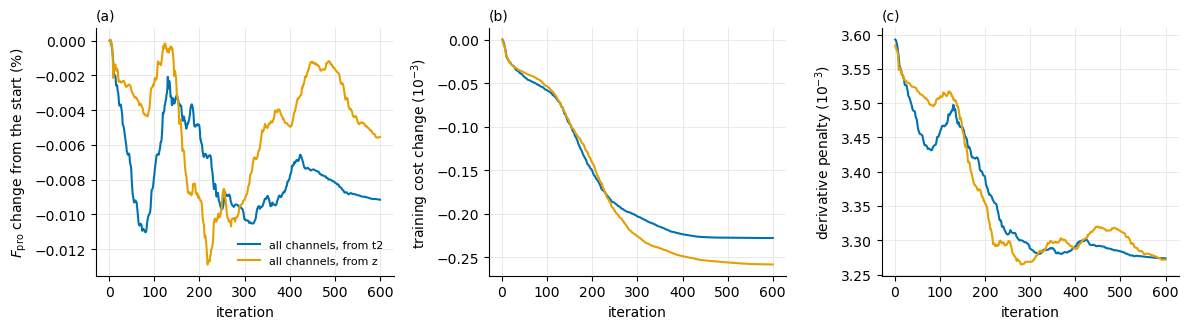

run,start F_pro,returned F_pro,last iterate F_pro,start cost,last cost,iterations,wall (h),returned,max|eta_1|,max|eta_2|,x pinned,stop
"all channels, from t2",0.960364,0.960364,0.960272,0.043231,0.043003,600,3.9,best_seen,0.0806,0.1005,0.00%,STOP: TOTAL NO. of ITERATIONS REACHED LIMIT
"all channels, from z",0.960326,0.960326,0.960270,0.043262,0.043004,600,3.9,best_seen,0.0763,0.1006,0.00%,STOP: TOTAL NO. of ITERATIONS REACHED LIMIT


In [4]:
# Training curves of the two all-channel runs (history = one row per L-BFGS-B iteration)
fig, axs = plt.subplots(1, 3, figsize=(12, 3.4))
for k, label in enumerate(["all channels, from t2", "all channels, from z"]):
    info, _ = RUNS[label]
    h = pd.DataFrame(info["history"])
    axs[0].plot(h.it, 100 * (h.F_pro - info["F_pro_start"]), color=OKABE[k], label=label)
    axs[1].plot(h.it, 1e3 * (h.cost - h.cost.iloc[0]), color=OKABE[k], label=label)
    axs[2].plot(h.it, 1e3 * h.deriv, color=OKABE[k], label=label)
axs[0].set_ylabel(r"$F_{\rm pro}$ change from the start (%)")
axs[1].set_ylabel(r"training cost change ($10^{-3}$)")
axs[2].set_ylabel(r"derivative penalty ($10^{-3}$)")
for ax, letter in zip(axs, "abc"):
    ax.set_xlabel("iteration")
    ax.set_title(f"({letter})", loc="left", fontsize=10)
    tidy(ax)
axs[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig("figures/tail_experiments_training.png", dpi=150)
plt.show()
runs4 = pd.DataFrame([{"run": label, "start F_pro": info["F_pro_start"], "returned F_pro": info["F_pro"],
                       "last iterate F_pro": info["history"][-1]["F_pro"],
                       "start cost": info["history"][0]["cost"], "last cost": info["history"][-1]["cost"],
                       "iterations": info["nit"], "wall (h)": info["wall_s"] / 3600,
                       "returned": info["returned"], "max|eta_1|": info["max_eta_1"], "max|eta_2|": info["max_eta_2"],
                       "x pinned": info["frac_preimage_pinned"], "stop": info["message"]}
                      for label, (info, _) in RUNS.items() if info.get("channels") == "shirol"])
display(runs4.style.hide(axis="index").format({"start F_pro": "{:.6f}", "returned F_pro": "{:.6f}",
                                               "last iterate F_pro": "{:.6f}", "start cost": "{:.6f}",
                                               "last cost": "{:.6f}", "wall (h)": "{:.1f}",
                                               "max|eta_1|": "{:.4f}", "max|eta_2|": "{:.4f}", "x pinned": "{:.2%}"}))

**Figure 1 and Table 3.** Training under the Shirol full set. **(a)** $F_{\rm pro}$ never rises more than 7e-7 above its
start (at iteration 1). It then wanders down, as low as −0.013 %, and ends 0.006 % (z) to 0.009 % (t2) below the start. **(b)** The cost still falls, by 2.3e-4 (t2) and 2.6e-4 (z). **(c)** It falls because the
derivative penalty drops from 3.59e-3 to 3.27e-3. So with all channels on, the optimizer finds it cheaper to smooth the
waveforms than to raise the fidelity. Both starts end at the same cost (0.043003) and the same $F_{\rm pro}$ (0.96027).
Since no iterate beats the start by more than 7e-7, the trainer returns iteration 1 ("best seen"). **The returned
"all-channel" tails are the decay-trained tails, changed by at most 1e-4 in $\eta$** (Figure 2). Nothing hits the
optimizer box (0 % pinned). The last iterate is not saved; only its numbers in the history are.
*Symbols:* $F_{\rm pro}$ at $n_c = 16$, Shirol set; training cost = $1 - F_{\rm pro}$ + penalties; derivative penalty =
the smoothness term of the cost (weighted); max$|\eta_c|$ of the returned tail; x pinned = share of the optimizer
variable at its box.

## 5. Results: gain over the gate alone

Each tail is scored by `DGRAPE/fwm_tail_score.py` under its training noise and under noise and truncations it was not
trained on. Each condition has its own gate-alone and gate + idle reference (`tables/tail_experiments_heldout.csv`).
Figures 2 and 3 then show the trained waveforms in time and in frequency.

In [5]:
H = pd.read_csv("tables/tail_experiments_heldout.csv")
COND = {"train": "decay, n_c 16", "all_ch": "DGRAPE all_ch, n_c 16", "shirol": "Shirol, n_c 16 (training)",
        "shirol_nc_a": "Shirol, n_c 24", "shirol_nc_b": "Shirol, n_c 28"}
alone5 = H[H.kind == "alone"].set_index("condition").F_pro
tr = H[H.kind == "trained"].copy()
tr["run"] = tr.tag.map({v: k for k, v in TAGS.items()})
main = tr[tr.condition.isin(COND)].pivot(index="run", columns="condition", values="gain_vs_alone")[list(COND)] * 100
main.loc["(gate alone F_pro)"] = alone5[list(COND)]
main = main.loc[list(TAGS) + ["(gate alone F_pro)"]].rename(columns=COND)
display(main.style.format("{:+.3f}").format("{:.5f}", subset=pd.IndexSlice["(gate alone F_pro)", :]))
idle5 = tr[tr.condition.isin(["shirol", "shirol_nc_b"])].pivot(index="run", columns="condition", values="gain_vs_idle") * 100
print("gain vs gate + idle 0.8 us (Shirol, %):")
display(idle5.loc[list(TAGS)].rename(columns=COND).style.format("{:+.3f}"))

condition,"decay, n_c 16","DGRAPE all_ch, n_c 16","Shirol, n_c 16 (training)","Shirol, n_c 24","Shirol, n_c 28"
run,,,,,
"decay, QEC-teeth start",+0.321,+0.027,+0.044,+0.044,+0.044
"decay, zero start",+0.318,+0.023,+0.040,+0.040,+0.040
"all channels, from t2",+0.321,+0.027,+0.044,+0.044,+0.044
"all channels, from z",+0.318,+0.023,+0.040,+0.040,+0.040
(gate alone F_pro),0.96706,0.95733,0.95993,0.95993,0.95993


gain vs gate + idle 0.8 us (Shirol, %):


condition,"Shirol, n_c 16 (training)","Shirol, n_c 28"
run,,
"decay, QEC-teeth start",+2.218,+2.218
"decay, zero start",+2.214,+2.214
"all channels, from t2",+2.218,+2.218
"all channels, from z",+2.214,+2.214


**Table 4 and Table 5.** Gain over the gate alone (Table 4) and over the gate + 0.8 μs idle (Table 5), in %, by noise set and
truncation. Last row of Table 4: $F_{\rm pro}$ of the gate alone in that column. **Under the Shirol set the best tail gains
+0.044 % (t2 start; z start +0.040 %), the same at $n_c$ = 16, 24 and 28** (scores agree to 2e-8). The all-channel
retraining changes no gain by more than 1e-5 %, because it returned the start (§4). Against waiting instead
(gate + idle), the tail is +2.22 % ahead. The decay-set gain (+0.32 %) shrinks by 0.28 % when the extra channels are on.
*Symbols:* gain = $F_{\rm pro}$(gate + tail) − $F_{\rm pro}$(reference), same noise and truncation; $n_c = 16$ = gate run at
24 and cut, as in training; $n_c$ = 24, 28 = gate and tail both run there, no cut; decay / all-channels = training noise;
t2 / z = start.

all channels, from t2: max|change in eta| = 3.22e-05 (max|eta| 0.1005)
all channels, from z: max|change in eta| = 1.19e-04 (max|eta| 0.1006)


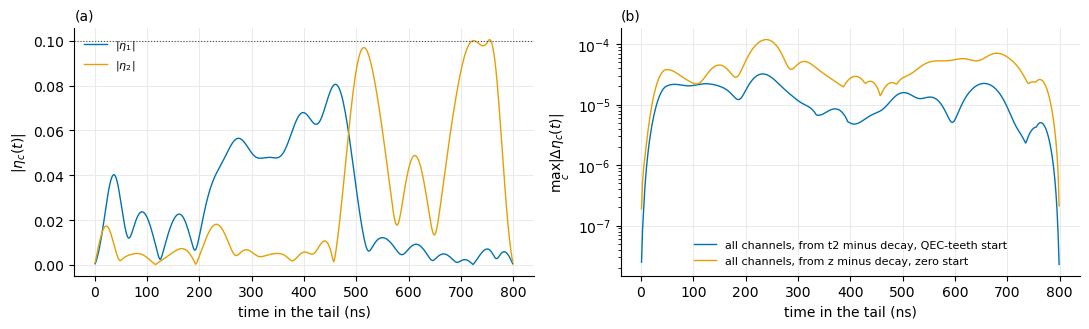

In [6]:
# Waveforms: the returned all-channel tail is the decay tail plus a tiny change; show both
t_ns = (np.arange(ft.n_steps(TAIL_US)) + 0.5) * DT * 1e3
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
for c in range(2):
    axs[0].plot(t_ns, np.abs(RUNS["all channels, from t2"][1][:, c]), color=OKABE[c], lw=1.0,
                label=rf"$|\eta_{c + 1}|$")
axs[0].axhline(ft.ETA_CAP, color="0.3", ls=":", lw=0.8)
axs[0].set_ylabel(r"$|\eta_c(t)|$")
axs[0].legend(frameon=False, fontsize=8, loc="upper left")
for k, (a, b) in enumerate([("decay, QEC-teeth start", "all channels, from t2"),
                            ("decay, zero start", "all channels, from z")]):
    d = np.abs(RUNS[b][1] - RUNS[a][1]).max(axis=1)
    axs[1].semilogy(t_ns, np.maximum(d, 1e-9), color=OKABE[k], lw=1.0, label=f"{b} minus {a}")
    print(f"{b}: max|change in eta| = {d.max():.2e} (max|eta| {np.abs(RUNS[a][1]).max():.4f})")
axs[1].set_ylabel(r"$\max_c |\Delta\eta_c(t)|$")
axs[1].legend(frameon=False, fontsize=8)
for ax, letter in zip(axs, "ab"):
    ax.set_xlabel("time in the tail (ns)")
    ax.set_title(f"({letter})", loc="left", fontsize=10)
    tidy(ax)
fig.tight_layout()
fig.savefig("figures/tail_experiments_waveforms.png", dpi=150)
plt.show()

**Figure 2.** **(a)** The returned all-channel tail (t2 start): one shot at the end of the tail, comb 1 first and comb 2 at the
cap. This is the waveform of `FWM_tails.ipynb` §6. **(b)** How much the all-channel training changed it: at most 3e-5
(t2) and 1e-4 (z), against amplitudes near 0.1. The two are the same tail.
*Symbols:* $|\eta_c(t)|$ comb amplitude (cap 0.1, dotted); $\Delta\eta_c$ = all-channel tail minus decay-trained tail,
same start.

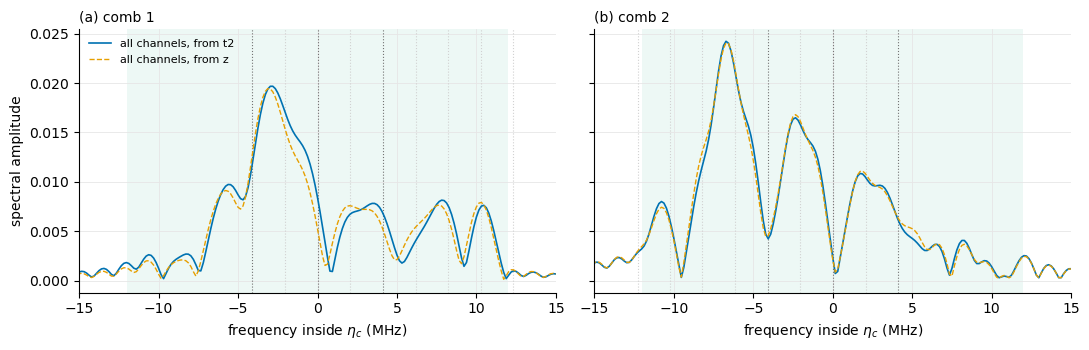

bare teeth inside eta_c:
 tooth n  comb 1 (MHz)  comb 2 (MHz)
       1         -4.14         +4.14
       3         +0.00         +0.01
       5         +4.12         -4.11
three largest peaks per comb and tail:
 comb                   run  peak (MHz)  height  nearest repair tooth n  offset from it (MHz)
    1 all channels, from t2      -2.812  +0.020                       1                +1.323
    1 all channels, from t2      -5.625  +0.010                       1                -1.490
    1 all channels, from t2      +7.812  +0.008                       5                +3.693
    1  all channels, from z      -3.125  +0.019                       1                +1.010
    1  all channels, from z      -5.781  +0.009                       1                -1.646
    1  all channels, from z     +10.312  +0.008                       5                +6.193
    2 all channels, from t2      -6.719  +0.024                       5                -2.612
    2 all channels, from t2      -2.

In [7]:
# Spectra of the two all-channel tails (frequency inside eta_c = offset from the frame carrier, comb-1 tooth 2 -> 3)
from scipy.signal import find_peaks

PAD = 8                                                    # zero padding: smoother curves, resolution stays 1/T
off = ft.tooth_offsets(16, ft.N_REF, fwm.FULL_PATHS)
teeth_mhz = [dict(zip(off["paths"], off[f"comb{c}"] / (2 * np.pi))) for c in (1, 2)]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
peaks = []
for c, ax in enumerate(axs):
    for n, x in zip(off["paths"], off[f"comb{c + 1}"] / (2 * np.pi)):
        ax.axvline(x, color="0.45" if n in ft.REPAIR_PATHS else "0.82", lw=0.8, ls=":")
    ax.axvspan(*ft.ETA_BAND, color=OKABE[2], alpha=0.07, lw=0)
    for k, label in enumerate(["all channels, from t2", "all channels, from z"]):
        eta = RUNS[label][1][:, c]
        n_pad = PAD * len(eta)
        freq = np.fft.fftshift(np.fft.fftfreq(n_pad, DT))  # MHz
        spec = np.abs(np.fft.fftshift(np.fft.fft(eta, n_pad))) / len(eta)
        ax.plot(freq, spec, color=OKABE[k], lw=1.2 if k == 0 else 1.0, ls="-" if k == 0 else "--", label=label)
        idx, _ = find_peaks(spec, height=0.2 * spec.max())
        for i in idx[np.argsort(spec[idx])[::-1]][:3]:      # the three largest
            near = min(ft.REPAIR_PATHS, key=lambda n: abs(teeth_mhz[c][n] - freq[i]))
            peaks.append({"comb": c + 1, "run": label, "peak (MHz)": freq[i], "height": spec[i],
                          "nearest repair tooth n": near, "offset from it (MHz)": freq[i] - teeth_mhz[c][near]})
    ax.set_xlim(-15, 15)
    ax.set_xlabel(r"frequency inside $\eta_c$ (MHz)")
    ax.set_title(f"({'ab'[c]}) comb {c + 1}", loc="left", fontsize=10)
    tidy(ax)
axs[0].set_ylabel("spectral amplitude")
axs[0].legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig("figures/tail_experiments_spectra.png", dpi=150)
plt.show()
tooth_tab = pd.DataFrame({"tooth n": off["paths"], "comb 1 (MHz)": off["comb1"] / (2 * np.pi),
                          "comb 2 (MHz)": off["comb2"] / (2 * np.pi)})
print("bare teeth inside eta_c:")
print(tooth_tab[tooth_tab["tooth n"].isin(ft.REPAIR_PATHS)].to_string(index=False, float_format="%+.2f"))
print("three largest peaks per comb and tail:")
print(pd.DataFrame(peaks).to_string(index=False, float_format="%+.3f"))

**Figure 3. Spectra of the two all-channel tails.** **(a)** comb 1, **(b)** comb 2. The frequency is measured inside
$\eta_c$, i.e. from the frame carrier (comb-1 tooth 2 → 3). Dotted lines: the bare teeth, darker for the three repair
teeth $n$ = 1, 3, 5. Green: the ±12 MHz band. The FFT is zero-padded 8× for smooth curves; the true resolution is
1/0.8 μs = 1.25 MHz, so features closer than that blend. The decay-trained tails are not drawn: they differ by
≤ 1e-4 in $\eta$ (Figure 2b), so their spectra lie on top of these.

- **Comb 2 has one peak per repair tooth, and all three are moved by the same amount:** −6.7 MHz (tooth 5 at −4.1,
  the largest), −2.3 MHz (tooth 3 at 0) and +1.7 to +1.9 MHz (tooth 1 at +4.1). That is a shift of about −2.4 MHz
  (−2.3 to −2.6) for every tooth.
- **Comb 1 puts most of its power near tooth 1:** its peak is at −2.8 MHz (t2) / −3.1 MHz (z), 1.0–1.3 MHz from the
  bare tooth at −4.1 MHz. Smaller features sit around +2 to +4 MHz (teeth 3 and 5), plus a side peak at −5.6 MHz and
  peaks near +8 and +10 MHz. The side peak and the peaks near +8 and +10 MHz match no repair tooth.
- The shifts have opposite signs on the two combs, as the pump Stark shift does (`fwm_tail.teeth_stark_shifts`: + on
  comb 1, − on comb 2). They also have the right size: 2π·538 MHz·$|\xi|^2$ gives 2.4 MHz at $|\xi| \approx 0.07$,
  comb 2's typical amplitude during its burst. **The tails aim at the Stark-shifted lines, not the bare teeth**, as
  `FWM_tails.ipynb` Figure C4 found for the decay-trained tails.
- The two starts give the same spectrum for comb 2. For comb 1 they differ only in detail (peak −2.8 vs −3.1 MHz,
  small differences at +2 to +8 MHz): one solution.

*Symbols:* $\eta_c$ = comb-$c$ waveform; spectral amplitude = $|{\rm FFT}(\eta_c)|/N$ with $N$ = 400 samples; tooth $n$ =
the comb line that serves the repair $n{-}1 \to n$ (comb 1) or empties $|n, f\rangle$ into the readout (comb 2);
$\xi$ = pump amplitude in the lab frame ($|\xi_c| = |\eta_c|$).

## 6. Where the gain goes: one channel group at a time

Why does the gain fall from +0.32 % to +0.04 %? We score the gate alone and gate + each tail with only one group of Shirol's
jump operators on (`DGRAPE/tail_experiments_channels.py` → `tables/tail_experiments_channels.csv`). "Closed" has no jumps.

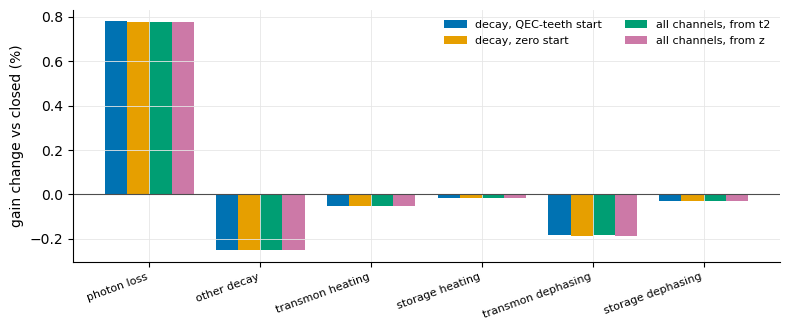

In [8]:
C = pd.read_csv("tables/tail_experiments_channels.csv")
C["run"] = C.tag.map({**{v: k for k, v in TAGS.items()}, "alone": "gate alone"})
GROUP_ORDER = ["closed", "photon loss", "other decay", "transmon heating", "storage heating",
               "transmon dephasing", "storage dephasing", "all"]
closed = C[C.group == "closed"].set_index("run").F_pro
C["cost (%)"] = 100 * (C.run.map(closed) - C.F_pro)
cost6 = C.pivot(index="group", columns="run", values="cost (%)").loc[GROUP_ORDER]
gain6 = (C[C.run != "gate alone"].pivot(index="group", columns="run", values="gain_vs_alone") * 100).loc[GROUP_ORDER]
gain6 = gain6 - gain6.loc["closed"]
table4 = pd.concat({"infidelity this group adds (%)": cost6[["gate alone"] + list(TAGS)],
                    "change of the tail's gain vs closed (%)": gain6[list(TAGS)]}, axis=1)
# Keep the halves apart: blue tint + left = cost, orange tint + right = gain change, thick line between them.
# One selector per entry: Styler scopes only the first part of a comma list to this table.
SEP = 1 + len(TAGS)                                         # first column of the right half
TINT = ["rgba(0, 114, 178, 0.10)", "rgba(230, 159, 0, 0.16)"]
styles = [{"selector": "th.col_heading.level0", "props": "text-align: center; border-bottom: 1px solid #888;"}]
for j in range(table4.shape[1]):
    for tag in ("th.col_heading", "td"):
        props = f"background-color: {TINT[j >= SEP]};"
        if j == SEP:
            props += " border-left: 3px solid currentColor;"
        styles.append({"selector": f"{tag}.col{j}", "props": props})
display(table4.style.format("{:+.3f}").set_table_styles(styles))
fig, ax = plt.subplots(figsize=(8, 3.4))
groups = GROUP_ORDER[1:-1]
w = 0.2
for k, run in enumerate(list(TAGS)):
    ax.bar(np.arange(len(groups)) + (k - 1.5) * w, gain6.loc[groups, run], w, color=OKABE[k], label=run)
ax.axhline(0, color="0.3", lw=0.8)
ax.set_xticks(np.arange(len(groups)))
ax.set_xticklabels(groups, rotation=20, ha="right", fontsize=8)
ax.set_ylabel("gain change vs closed (%)")
ax.legend(frameon=False, fontsize=8, ncol=2)
tidy(ax)
fig.tight_layout()
fig.savefig("figures/tail_experiments_channels.png", dpi=150)
plt.show()

**Table 6 and Figure 4.** Left half of Table 6 (blue, five columns): the infidelity each channel group adds on its own
(closed $F_{\rm pro}$ minus $F_{\rm pro}$ with that group only), in %. Right half (orange, four columns, after the thick
line) and Figure 4: how that group changes the tail's gain compared with the closed system.

- **Photon loss is the only channel the tail fixes:** it cuts the loss cost from 2.40 % (gate alone) to 1.62 %, a gain of
  +0.78 % over closed.
- **Every other channel costs the tail more than it costs the gate alone**, because the tail adds 0.8 μs of exposure, and its
  repair puts the transmon in $|f
angle$ and photons in the readout. Readout and transmon decay ("other decay") −0.25 %, transmon
  dephasing −0.19 %, transmon heating −0.05 %, storage dephasing −0.03 %, storage heating −0.01 %.
- The four channels the decay set leaves out cost −0.281 % one at a time. The drop from +0.321 % (decay set) to +0.044 %
  (Shirol set) is −0.277 %. So their costs add up. **Transmon dephasing is two thirds of the drop.**
- Inside the decay set, loss and "other decay" do not add up: one at a time they predict +0.51 %, together they give
  +0.32 %. We have not explained this yet.
- Closed, the tail costs 0.014 %: a coherent error, the same for every run.

Each all-channel run and the decay run from the same start agree to better than 1e-3 % in every row.
*Symbols:* closed = no jump operators; group names as in Table 1 (other decay = $\kappa_r$ + transmon $T_1$, heating includes
the pumps' extra heating); all = Shirol full set; gain change = gain(group only) − gain(closed).

## 7. Verdict

The cell below applies the rule fixed in §1 to Table 4.

In [9]:
# The break-even rule of section 1, checked on the numbers above
best = max(["all channels, from t2", "all channels, from z"],
           key=lambda r: tr[(tr.run == r) & (tr.condition == "shirol")].gain_vs_alone.iloc[0])
g = {c: tr[(tr.run == best) & (tr.condition == c)].gain_vs_alone.iloc[0] for c in ("shirol", "shirol_nc_b")}
other = [r for r in ("all channels, from t2", "all channels, from z") if r != best][0]
spread = abs(g["shirol"] - tr[(tr.run == other) & (tr.condition == "shirol")].gain_vs_alone.iloc[0])
dec = tr[(tr.run == "decay, QEC-teeth start") & (tr.condition == "shirol")].gain_vs_alone.iloc[0]
print(f"better start: {best}")
print(f"gain vs gate alone, Shirol full set: n_c 16 (cut) {100 * g['shirol']:+.4f} %, n_c 28 {100 * g['shirol_nc_b']:+.4f} %")
print(f"spread between the two starts: {100 * spread:.4f} %;  decay-trained tail under the same noise: {100 * dec:+.4f} %")
p16 = H[H.condition == "shirol"].set_index(["kind", "tag"]).F_pro
for c in ("shirol_nc_a", "shirol_nc_b"):
    d = (H[H.condition == c].set_index(["kind", "tag"]).F_pro - p16).abs().max()
    print(f"max |F_pro({c}) - F_pro(n_c 16)| over all rows: {d:.1e}")
print("BREAKS EVEN" if min(g.values()) > 0 else "DOES NOT BREAK EVEN")

better start: all channels, from t2
gain vs gate alone, Shirol full set: n_c 16 (cut) +0.0436 %, n_c 28 +0.0436 %
spread between the two starts: 0.0038 %;  decay-trained tail under the same noise: +0.0435 %
max |F_pro(shirol_nc_a) - F_pro(n_c 16)| over all rows: 4.4e-16
max |F_pro(shirol_nc_b) - F_pro(n_c 16)| over all rows: 1.6e-08
BREAKS EVEN


**Verdict: the tail breaks even, but only just.** With every one of Shirol's error channels on, in the gate as well as the
tail, gate + 0.8 μs tail beats the gate alone by **+0.044 %** ($F_{\rm pro}$ 0.96036 vs 0.95993). This holds at the
training truncation and held out at $n_c$ = 24 and 28. The other start gives +0.040 %, a spread of 0.004 %. The margin is
about 11 times the spread. It is not robust: a 10 % error in pump strength costs 8–13 % (decay set, conditions
`eta_x0.9` and `eta_x1.1` in `tables/tail_experiments_heldout.csv`).

**Conclusions**

1. **Training with all channels on found nothing new.** From both decay-trained starts, 600 iterations under the Shirol
   set never raised $F_{\rm pro}$ by more than 7e-7. The optimizer lowered the cost only by smoothing the waveforms, which
   cost 0.006–0.009 % in $F_{\rm pro}$, and the trainer returned the start. Within this cost and from these starts,
   the decay-trained tail is already the best all-channel tail. So answer (1) of §1 holds: the tail is right, and the
   extra noise simply costs more during its 0.8 μs.
2. **The decay-trained tail already broke even** under the Shirol set (§3, +0.044 %). It is the same number before and
   after training.
3. **The extra channels cost the tail 0.28 %**, and they add up. Transmon dephasing alone is 0.19 %, heating 0.05 %,
   storage dephasing and heating 0.04 %. The old DGRAPE `all_ch` set gives a lower gain (+0.027 %). It differs mainly in the
   storage dephasing: 0.58 vs 0.23 ms⁻¹, so part of it is counted twice.
4. **The tail is a real photon-loss repair** (+0.78 % with loss only, −0.01 % closed). Everything else it does costs
   fidelity.

**Next steps (not run)**

- Train **without the derivative penalty** (or with a much smaller weight) under the Shirol set, to test whether the
  penalty is what holds $F_{\rm pro}$ at the start. The decay-trained tail was balanced against the same penalty.
- **A cold start under the Shirol set** (QEC teeth, zero), to look for an optimum that spends less time with the transmon
  excited (a shorter or later shot) and so less dephasing.
- **Shorter tails** (0.5–0.6 μs). The tail's non-loss costs grow with its length.
- Robust training over pump strength ±10 %, since the margin is far smaller than the pump sensitivity.